In [1]:
import os; os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
SPLITS, RESULTS = ROOT / "data" / "splits", ROOT / "results"
RESULTS.mkdir(exist_ok=True)

from src.utils import get_device, seed_everything
seed_everything(42)
print("Repo root:", ROOT, "| Device:", get_device())

Repo root: /Users/shraapteshlokanda/chestscope | Device: mps


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from src.make_splits import build_inventory, find_data_root
sns.set_theme(style="whitegrid")
print("Data root:", find_data_root())

Data root: /Users/shraapteshlokanda/chestscope/data/raw/chest_xray/chest_xray


## 1. File inventory

In [3]:
df = build_inventory()
df["aspect"] = df.w / df.h
print(len(df), "images")
df.head()

5856 images


,path,split,label,w,h,mode,y,group,aspect
0,/Users/shraapteshlokanda/chestscope/data/raw/c...,train,NORMAL,2090,1858,L,0,IM-0115,1.124865
1,/Users/shraapteshlokanda/chestscope/data/raw/c...,train,NORMAL,1422,1152,L,0,IM-0117,1.234375
2,/Users/shraapteshlokanda/chestscope/data/raw/c...,train,NORMAL,1810,1434,L,0,IM-0119,1.262204
3,/Users/shraapteshlokanda/chestscope/data/raw/c...,train,NORMAL,1618,1279,L,0,IM-0122,1.265051
4,/Users/shraapteshlokanda/chestscope/data/raw/c...,train,NORMAL,1600,1125,L,0,IM-0125,1.422222


## 2. Class balance

label,NORMAL,PNEUMONIA,pneumonia_pct
split,,,
test,234,390,62.5
train,1341,3875,74.3
val,8,8,50.0


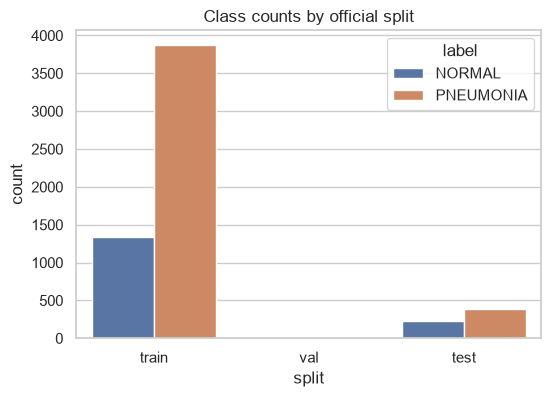

In [4]:
counts = df.groupby(["split", "label"]).size().unstack()
counts["pneumonia_pct"] = (counts.PNEUMONIA / (counts.NORMAL + counts.PNEUMONIA) * 100).round(1)
display(counts)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="split", hue="label", order=["train", "val", "test"], ax=ax)
ax.set_title("Class counts by official split")
fig.savefig(RESULTS / "class_counts.png", dpi=200, bbox_inches="tight")

## 3. Image properties

mode
L      5573
RGB     283
Name: count, dtype: int64


,w,h,aspect
count,5856.00,5856.00,5856.00
mean,1327.88,970.69,1.44
std,363.50,383.39,0.25
min,384.00,127.00,0.84
25%,1056.00,688.00,1.26
50%,1281.00,888.00,1.42
75%,1560.00,1187.00,1.59
max,2916.00,2713.00,3.38


,w,h
label,,
NORMAL,1654.0,1323.0
PNEUMONIA,1160.0,776.0


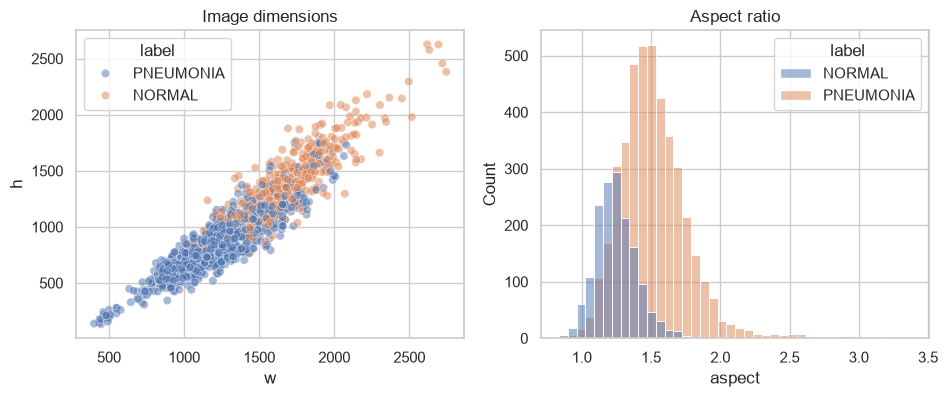

In [5]:
print(df["mode"].value_counts())
display(df[["w", "h", "aspect"]].describe().round(2))
display(df.groupby("label")[["w", "h"]].median())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df.sample(1500, random_state=42), x="w", y="h", hue="label", alpha=.5, ax=axes[0])
sns.histplot(data=df, x="aspect", hue="label", bins=40, ax=axes[1])
axes[0].set_title("Image dimensions"); axes[1].set_title("Aspect ratio")
fig.savefig(RESULTS / "image_sizes.png", dpi=200, bbox_inches="tight")

## 4. Sample images

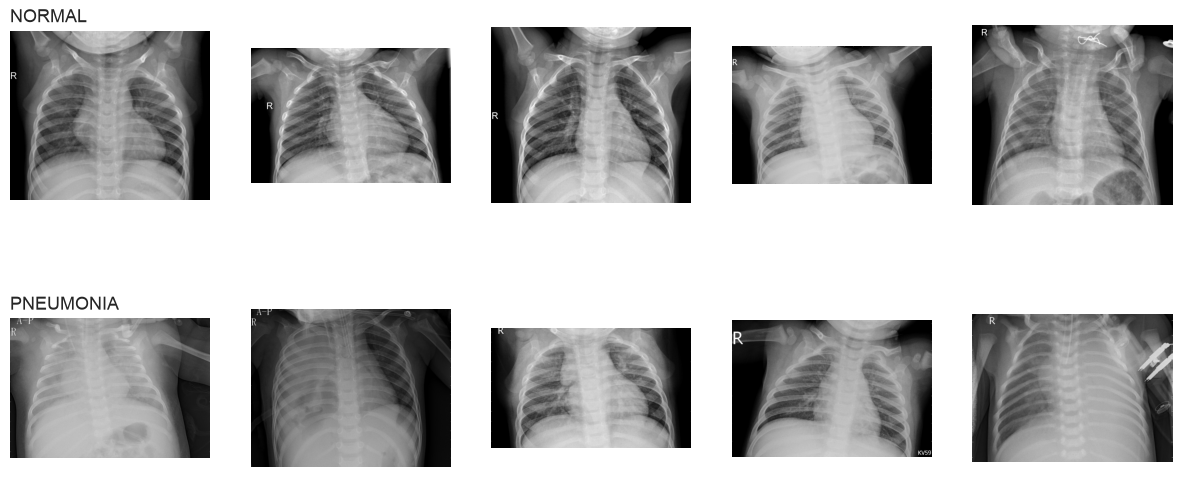

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for r, label in enumerate(["NORMAL", "PNEUMONIA"]):
    sub = df[(df.label == label) & (df.split == "train")].sample(5, random_state=0)
    for c, p in enumerate(sub.path):
        axes[r, c].imshow(np.array(Image.open(p).convert("L")), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=13)
fig.savefig(RESULTS / "sample_grid.png", dpi=200, bbox_inches="tight")

## 5. Pixel intensity check (shortcut detection)

mean           std       
            mean    std   mean    std
label                                
NORMAL     0.487  0.054  0.241  0.022
PNEUMONIA  0.483  0.077  0.220  0.037

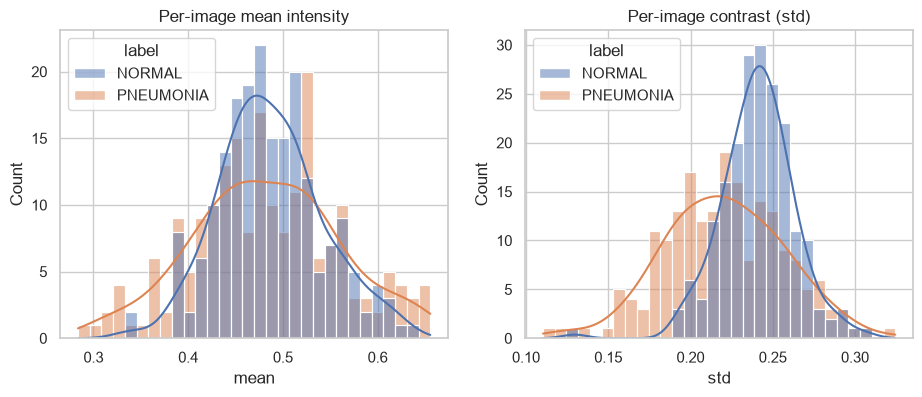

In [7]:
samp = df.groupby("label").sample(200, random_state=42)
stats = []
for p, label in zip(samp.path, samp.label):
    a = np.array(Image.open(p).convert("L"), dtype=np.float32) / 255
    stats.append(dict(label=label, mean=a.mean(), std=a.std()))
stats = pd.DataFrame(stats)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=stats, x="mean", hue="label", bins=30, kde=True, ax=axes[0])
sns.histplot(data=stats, x="std", hue="label", bins=30, kde=True, ax=axes[1])
axes[0].set_title("Per-image mean intensity"); axes[1].set_title("Per-image contrast (std)")
fig.savefig(RESULTS / "intensity.png", dpi=200, bbox_inches="tight")
display(stats.groupby("label").agg(["mean", "std"]).round(3))

## 6. Patient-leakage audit (official splits)

In [8]:
per_pt = df.groupby("group").size()
print(f"{df.group.nunique()} patient groups; images per group:")
display(per_pt.describe().round(2))

sets = {s: set(df[df.split == s].group) for s in ["train", "val", "test"]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a} & {b}: {len(sets[a] & sets[b])} shared patient groups")

fallback = df[df.group == df.path.map(lambda p: Path(p).name)]
print("Unparsed filenames (own group):", len(fallback))
display(fallback.path.head())

2790 patient groups; images per group:


count    2790.00
mean        2.10
std         1.82
min         1.00
25%         1.00
50%         2.00
75%         2.00
max        31.00
dtype: float64

train & val: 0 shared patient groups
train & test: 264 shared patient groups
val & test: 0 shared patient groups
Unparsed filenames (own group): 0


Series([], Name: path, dtype: str)

## 7. Verify the saved patient-grouped splits

In [9]:
train_df, val_df, test_df = [pd.read_csv(SPLITS / f"{s}.csv") for s in ["train", "val", "test"]]
assert set(train_df.group).isdisjoint(val_df.group), "Patient leakage train/val!"
assert set(train_df.path).isdisjoint(val_df.path)
assert set(train_df.path).isdisjoint(test_df.path) and set(val_df.path).isdisjoint(test_df.path)
print("Integrity checks passed: no patient or image overlap between train and val; test held out.")

summary = pd.DataFrame({
    "n_images": [len(train_df), len(val_df), len(test_df)],
    "pneumonia_pct": [d.y.mean() * 100 for d in (train_df, val_df, test_df)],
    "patient_groups": [d.group.nunique() for d in (train_df, val_df, test_df)],
}, index=["train", "val", "test"]).round(1)
display(summary)
pos_weight = (train_df.y == 0).sum() / (train_df.y == 1).sum()
print("pos_weight (n_neg / n_pos):", round(pos_weight, 3))

Integrity checks passed: no patient or image overlap between train and val; test held out.


,n_images,pneumonia_pct,patient_groups
train,4185,74.2,2120
val,1047,74.2,530
test,624,62.5,404


pos_weight (n_neg / n_pos): 0.347


## 8. Augmentation check

torch.Size([16, 3, 224, 224]) torch.Size([16])


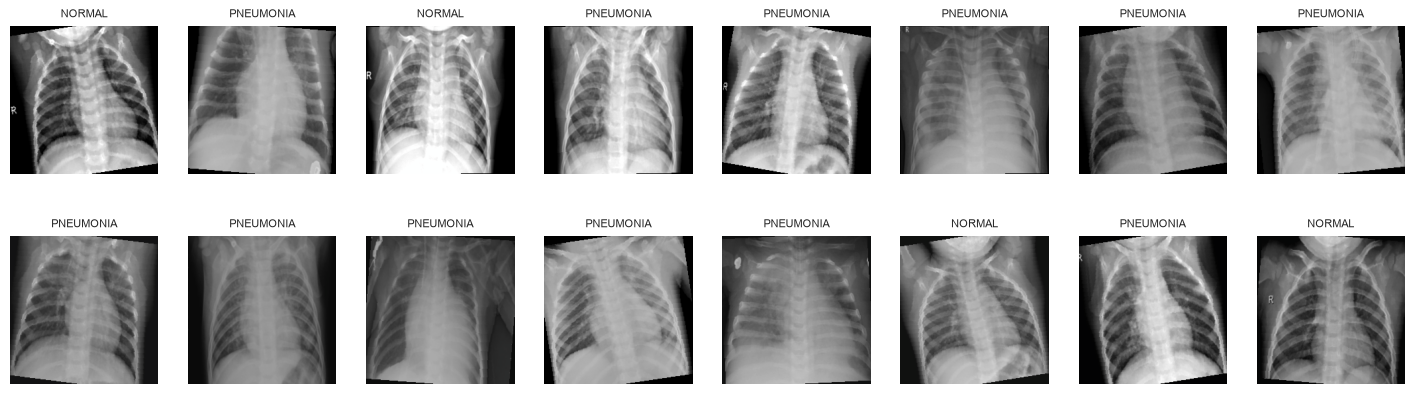

In [10]:
from src.data import get_loaders
train_loader, _, _ = get_loaders(bs=16, workers=0)
x, y = next(iter(train_loader))
print(x.shape, y.shape)   # expect [16, 3, 224, 224], [16]

mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
def denorm(t): return (t.permute(1, 2, 0).numpy() * std + mean).clip(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, img, lab in zip(axes.ravel(), x, y):
    ax.imshow(denorm(img)); ax.set_title("PNEUMONIA" if lab else "NORMAL", fontsize=8); ax.axis("off")
fig.savefig(RESULTS / "augmented_batch.png", dpi=200, bbox_inches="tight")

## 9. Findings summary
- Dataset size, class counts, and pneumonia % per official split: 
- Image size / mode findings (why resize to 224x224):
- Intensity or size differences between classes (shortcut risk): 
- Leakage audit: shared patient groups across official splits:
- Split design: patient-grouped train/val from pooled train+val; official test held out. Final sizes:
- pos_weight: 
- Limitations: pediatric single-center data; train/test distribution shift; 16-image official val set; label noise